# Experiment 12: Project RESCUE-SWARM
## Cooperative Multi-Agent Reinforcement Learning

**Aim:** Develop a multi-agent reinforcement learning system in which rescue agents learn to coordinate their actions in a disaster environment.

### Objectives
1. Design a grid environment with rescue agents, victims, obstacles, and hazardous cells.
2. Define state, action, and reward representations.
3. Implement independent Q-learning for each rescue agent.
4. Implement cooperative learning using shared information and a common team reward.
5. Visualize agent movements, rescue progress, and learning curves.
6. Compare both approaches using successful rescues, completion time, cumulative rewards, and collisions.

**Approach:** This notebook uses a small tabular grid-world so the learning process is easy to understand and run without external datasets. The independent method gives each agent its own reward and local state. The cooperative method shares the team reward and uses a compact shared state describing the nearest remaining victim. This is a simplified educational simulation, not a real-world emergency-response planner.

## 1. Import libraries and set configuration

In [1]:
import random
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

GRID_SIZE = 7
N_AGENTS = 2
N_VICTIMS = 4
N_EPISODES = 250
MAX_STEPS = 100

# Actions: up, down, left, right, stay
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1), (0, 0)]
ACTION_NAMES = ["Up", "Down", "Left", "Right", "Stay"]

ALPHA = 0.15       # learning rate
GAMMA = 0.95       # discount factor
EPSILON_START = 1.0
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.985

print("Libraries loaded. Grid:", GRID_SIZE, "x", GRID_SIZE)

Libraries loaded. Grid: 7 x 7


## 2. Design the disaster environment

The environment contains two rescue agents, four victims, fixed obstacles, and hazardous cells. Agents cannot pass through obstacles. Entering a hazard incurs a penalty. A victim is rescued when an agent reaches that victim's cell; each victim can be rescued only once.

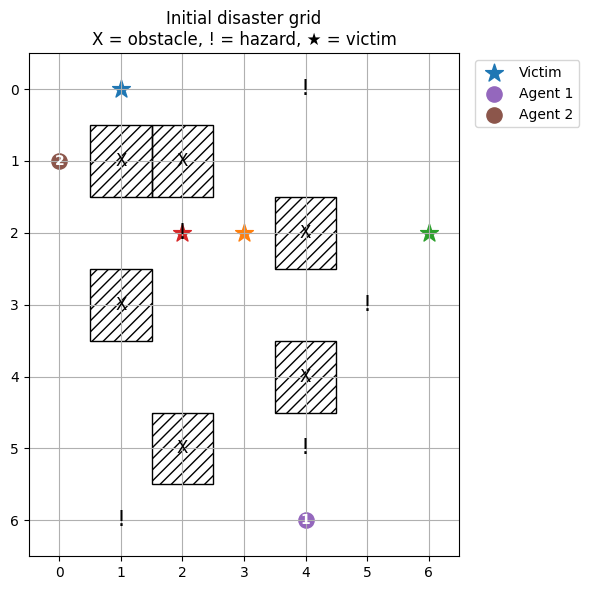

In [2]:
class RescueEnvironment:
    def __init__(self, grid_size=GRID_SIZE, n_agents=N_AGENTS, n_victims=N_VICTIMS,
                 max_steps=MAX_STEPS, seed=None):
        self.grid_size = grid_size
        self.n_agents = n_agents
        self.n_victims = n_victims
        self.max_steps = max_steps
        self.rng = random.Random(seed)

        # Fixed map elements; starts/victims are sampled to avoid blocked cells.
        self.obstacles = {(1, 1), (1, 2), (2, 4), (3, 1), (4, 4), (5, 2)}
        self.hazards = {(0, 4), (2, 2), (3, 5), (5, 4), (6, 1)}

        self.free_cells = [
            (r, c) for r in range(grid_size) for c in range(grid_size)
            if (r, c) not in self.obstacles
        ]

    def reset(self):
        chosen = self.rng.sample(self.free_cells, self.n_agents + self.n_victims)
        self.agent_positions = chosen[:self.n_agents]
        self.victims = set(chosen[self.n_agents:])
        self.rescued = set()
        self.steps = 0
        self.collisions = 0
        self.total_reward = 0.0
        return self.get_local_states()

    def get_local_states(self):
        # Each agent observes its own position and the nearest remaining victim.
        states = []
        remaining = sorted(self.victims)
        for pos in self.agent_positions:
            if remaining:
                target = min(remaining, key=lambda v: abs(v[0]-pos[0]) + abs(v[1]-pos[1]))
                dr = int(np.sign(target[0] - pos[0]))
                dc = int(np.sign(target[1] - pos[1]))
            else:
                dr, dc = 0, 0
            states.append((pos[0], pos[1], dr, dc))
        return states

    def get_shared_state(self, agent_index):
        # Cooperative state includes local position and the nearest remaining victim direction.
        return self.get_local_states()[agent_index]

    def step(self, actions):
        rewards = [-0.1] * self.n_agents  # small cost for every step
        old_positions = list(self.agent_positions)
        proposed = []

        for i, action_idx in enumerate(actions):
            dr, dc = ACTIONS[action_idx]
            r, c = old_positions[i]
            nxt = (r + dr, c + dc)
            if not (0 <= nxt[0] < self.grid_size and 0 <= nxt[1] < self.grid_size):
                nxt = old_positions[i]
                rewards[i] -= 0.25
            if nxt in self.obstacles:
                nxt = old_positions[i]
                rewards[i] -= 0.5
            proposed.append(nxt)

        # Collision penalty if agents attempt to occupy the same cell.
        if len(set(proposed)) < len(proposed):
            self.collisions += 1
            for i in range(self.n_agents):
                if proposed[i] == proposed[1-i]:
                    rewards[i] -= 1.0
                    proposed[i] = old_positions[i]

        self.agent_positions = proposed
        for i, pos in enumerate(self.agent_positions):
            if pos in self.hazards:
                rewards[i] -= 1.0
            if pos in self.victims:
                self.victims.remove(pos)
                self.rescued.add(pos)
                rewards[i] += 10.0

        self.steps += 1
        done = (len(self.victims) == 0) or (self.steps >= self.max_steps)
        self.total_reward += sum(rewards)
        return self.get_local_states(), rewards, done, {
            "rescued": len(self.rescued),
            "collisions": self.collisions,
            "steps": self.steps,
            "team_reward": sum(rewards)
        }

def draw_environment(env, title="Rescue environment"):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xlim(-0.5, env.grid_size - 0.5)
    ax.set_ylim(env.grid_size - 0.5, -0.5)
    ax.set_xticks(range(env.grid_size))
    ax.set_yticks(range(env.grid_size))
    ax.set_xticklabels(range(env.grid_size))
    ax.set_yticklabels(range(env.grid_size))
    ax.grid(True)
    for r, c in env.obstacles:
        ax.add_patch(plt.Rectangle((c-0.5, r-0.5), 1, 1, hatch="///", fill=False))
        ax.text(c, r, "X", ha="center", va="center", fontsize=12)
    for r, c in env.hazards:
        ax.text(c, r, "!", ha="center", va="center", fontsize=16)
    for r, c in env.victims:
        ax.scatter(c, r, marker="*", s=180, label="Victim" if (r, c) == min(env.victims) else None)
    for i, (r, c) in enumerate(env.agent_positions):
        ax.scatter(c, r, marker="o", s=120, label=f"Agent {i+1}")
        ax.text(c, r, str(i+1), ha="center", va="center", color="white", weight="bold")
    ax.set_title(title + "\nX = obstacle, ! = hazard, ★ = victim")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

demo_env = RescueEnvironment(seed=SEED)
demo_env.reset()
draw_environment(demo_env, "Initial disaster grid")

## 3. States, actions, and rewards

**State:** `(row, column, direction_to_nearest_victim_row, direction_to_nearest_victim_column)`. The target direction components are -1, 0, or +1.

**Actions:** Up, Down, Left, Right, Stay.

**Rewards:** +10 for rescuing a victim, -0.1 per step, -0.25 for trying to leave the grid, -0.5 for attempting to enter an obstacle, -1 for entering a hazardous cell, and -1 for a collision. These values encourage safe, efficient movement.

In [3]:
def epsilon_greedy(q_table, state, epsilon, rng):
    if rng.random() < epsilon:
        return rng.randrange(len(ACTIONS))
    values = q_table[state]
    best = np.flatnonzero(values == values.max())
    return int(rng.choice(list(best)))

def q_update(q_table, state, action, reward, next_state, done):
    current = q_table[state][action]
    future = 0.0 if done else np.max(q_table[next_state])
    q_table[state][action] = current + ALPHA * (reward + GAMMA * future - current)

def new_q_table():
    return defaultdict(lambda: np.zeros(len(ACTIONS), dtype=float))

print("State example:", demo_env.get_local_states()[0])
print("Action set:", ACTION_NAMES)

State example: (6, 4, -1, -1)
Action set: ['Up', 'Down', 'Left', 'Right', 'Stay']


## 4. Train independent Q-learning agents

Each agent learns a separate Q-table and receives its own individual reward. Agents do not receive a shared team reward. They still operate in the same environment, so their movement can affect collision outcomes.

In [4]:
def train_independent(episodes=N_EPISODES, seed=SEED):
    rng = random.Random(seed)
    env = RescueEnvironment(seed=seed)
    q_tables = [new_q_table() for _ in range(N_AGENTS)]
    records = []

    for ep in range(episodes):
        states = env.reset()
        epsilon = max(EPSILON_MIN, EPSILON_START * (EPSILON_DECAY ** ep))
        ep_reward = 0.0

        for _ in range(env.max_steps):
            actions = [
                epsilon_greedy(q_tables[i], states[i], epsilon, rng)
                for i in range(N_AGENTS)
            ]
            next_states, rewards, done, info = env.step(actions)
            for i in range(N_AGENTS):
                q_update(q_tables[i], states[i], actions[i], rewards[i], next_states[i], done)
            states = next_states
            ep_reward += sum(rewards)
            if done:
                break

        records.append({
            "episode": ep + 1,
            "rescued": info["rescued"],
            "steps": info["steps"],
            "collisions": info["collisions"],
            "cumulative_reward": ep_reward
        })
    return q_tables, pd.DataFrame(records)

independent_q, independent_history = train_independent()
display(independent_history.tail())
print("Independent Q-learning training complete.")

,episode,rescued,steps,collisions,cumulative_reward
245,246,4,9,1,36.7
246,247,4,10,0,34.0
247,248,4,9,0,37.2
248,249,4,10,0,34.5
249,250,4,14,0,36.7


Independent Q-learning training complete.


## 5. Train cooperative Q-learning agents

For this cooperative variant, agents receive a common team reward equal to the sum of individual rewards. Each agent still has its own Q-table, but both update from the shared team outcome. Agents also use the same target-direction state representation, which exposes useful task information. This is a simple cooperative baseline rather than a centralized joint-action algorithm.

In [5]:
def train_cooperative(episodes=N_EPISODES, seed=SEED + 1000):
    rng = random.Random(seed)
    env = RescueEnvironment(seed=seed)
    q_tables = [new_q_table() for _ in range(N_AGENTS)]
    records = []

    for ep in range(episodes):
        states = env.reset()
        epsilon = max(EPSILON_MIN, EPSILON_START * (EPSILON_DECAY ** ep))
        ep_reward = 0.0

        for _ in range(env.max_steps):
            actions = [
                epsilon_greedy(q_tables[i], env.get_shared_state(i), epsilon, rng)
                for i in range(N_AGENTS)
            ]
            next_states, individual_rewards, done, info = env.step(actions)
            team_reward = sum(individual_rewards)
            for i in range(N_AGENTS):
                state = states[i]
                next_state = next_states[i]
                q_update(q_tables[i], state, actions[i], team_reward, next_state, done)
            states = next_states
            ep_reward += team_reward
            if done:
                break

        records.append({
            "episode": ep + 1,
            "rescued": info["rescued"],
            "steps": info["steps"],
            "collisions": info["collisions"],
            "cumulative_reward": ep_reward
        })
    return q_tables, pd.DataFrame(records)

cooperative_q, cooperative_history = train_cooperative()
display(cooperative_history.tail())
print("Cooperative Q-learning training complete.")

,episode,rescued,steps,collisions,cumulative_reward
245,246,3,100,0,-3.25
246,247,4,51,0,25.05
247,248,2,100,0,-3.25
248,249,1,100,0,-15.00
249,250,4,27,0,30.60


Cooperative Q-learning training complete.


## 6. Plot learning curves

The plots show episode-level performance and a smoothed reward curve. Because this is a stochastic environment, performance can vary from episode to episode.

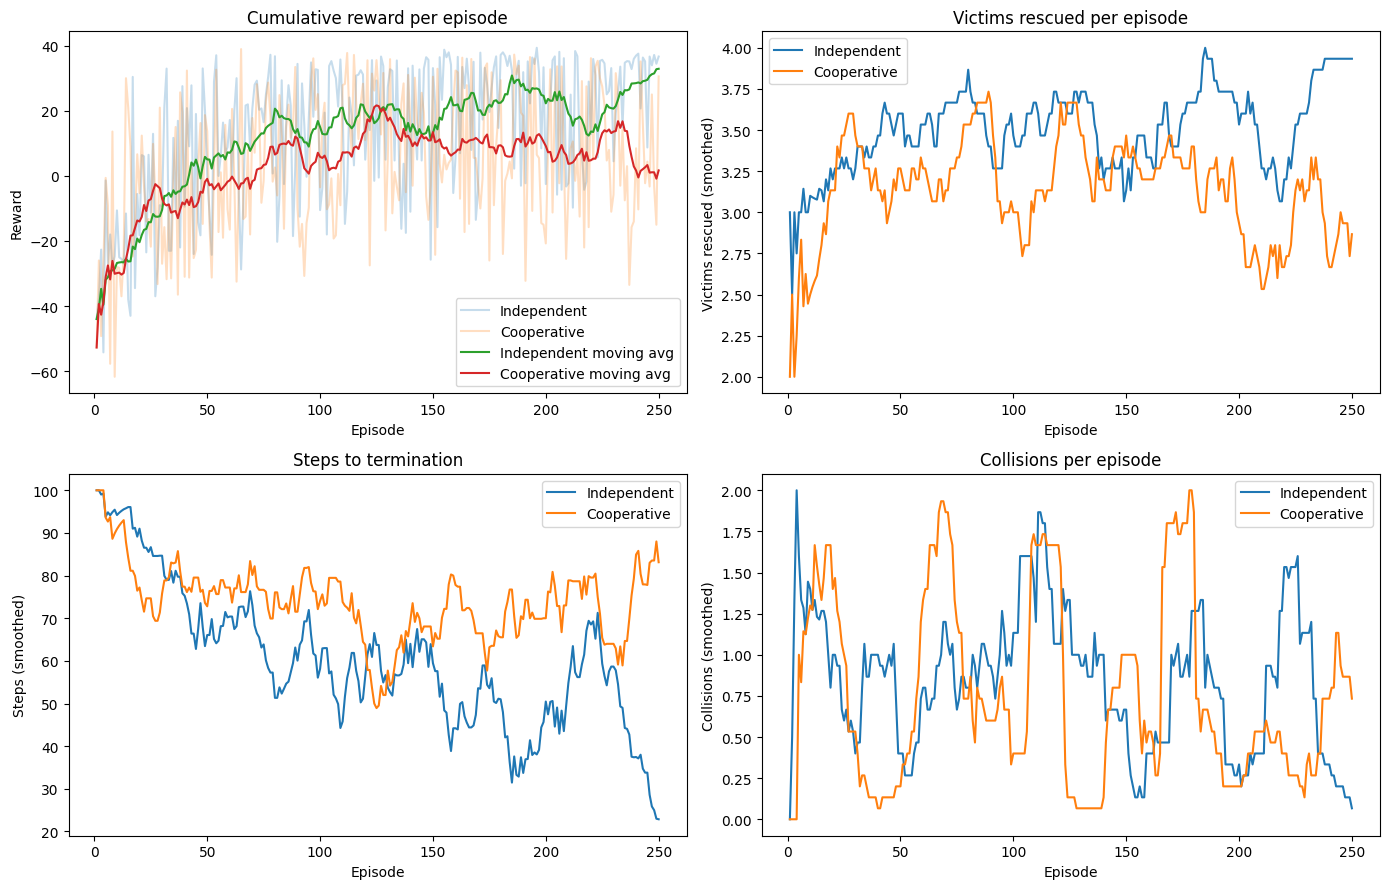

In [6]:
def moving_average(values, window=15):
    return pd.Series(values).rolling(window, min_periods=1).mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(independent_history["episode"], independent_history["cumulative_reward"], alpha=0.25, label="Independent")
axes[0, 0].plot(cooperative_history["episode"], cooperative_history["cumulative_reward"], alpha=0.25, label="Cooperative")
axes[0, 0].plot(independent_history["episode"], moving_average(independent_history["cumulative_reward"]), label="Independent moving avg")
axes[0, 0].plot(cooperative_history["episode"], moving_average(cooperative_history["cumulative_reward"]), label="Cooperative moving avg")
axes[0, 0].set_title("Cumulative reward per episode")
axes[0, 0].set_xlabel("Episode")
axes[0, 0].set_ylabel("Reward")
axes[0, 0].legend()

axes[0, 1].plot(independent_history["episode"], moving_average(independent_history["rescued"]), label="Independent")
axes[0, 1].plot(cooperative_history["episode"], moving_average(cooperative_history["rescued"]), label="Cooperative")
axes[0, 1].set_title("Victims rescued per episode")
axes[0, 1].set_xlabel("Episode")
axes[0, 1].set_ylabel("Victims rescued (smoothed)")
axes[0, 1].legend()

axes[1, 0].plot(independent_history["episode"], moving_average(independent_history["steps"]), label="Independent")
axes[1, 0].plot(cooperative_history["episode"], moving_average(cooperative_history["steps"]), label="Cooperative")
axes[1, 0].set_title("Steps to termination")
axes[1, 0].set_xlabel("Episode")
axes[1, 0].set_ylabel("Steps (smoothed)")
axes[1, 0].legend()

axes[1, 1].plot(independent_history["episode"], moving_average(independent_history["collisions"]), label="Independent")
axes[1, 1].plot(cooperative_history["episode"], moving_average(cooperative_history["collisions"]), label="Cooperative")
axes[1, 1].set_title("Collisions per episode")
axes[1, 1].set_xlabel("Episode")
axes[1, 1].set_ylabel("Collisions (smoothed)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 7. Evaluate both approaches

To compare learned policies fairly, evaluate them without exploration (greedy action selection) over multiple fresh episodes. The evaluation uses the same map layout and seed sequence for both approaches, though randomly sampled start/victim locations are stochastic.

In [7]:
def evaluate_policy(q_tables, cooperative=False, n_eval=60, seed=2026):
    results = []
    for ep in range(n_eval):
        env = RescueEnvironment(seed=seed + ep)
        states = env.reset()
        total_reward = 0.0

        for _ in range(env.max_steps):
            actions = []
            for i in range(N_AGENTS):
                state = env.get_shared_state(i) if cooperative else states[i]
                values = q_tables[i][state]
                actions.append(int(np.argmax(values)))
            next_states, rewards, done, info = env.step(actions)
            total_reward += sum(rewards)
            states = next_states
            if done:
                break

        results.append({
            "rescued": info["rescued"],
            "steps": info["steps"],
            "cumulative_reward": total_reward,
            "collisions": info["collisions"],
            "all_victims_rescued": int(info["rescued"] == N_VICTIMS)
        })
    return pd.DataFrame(results)

ind_eval = evaluate_policy(independent_q, cooperative=False)
coop_eval = evaluate_policy(cooperative_q, cooperative=True)

summary = pd.DataFrame([
    {
        "Approach": "Independent Q-learning",
        "Mean victims rescued": ind_eval["rescued"].mean(),
        "All victims rescued (%)": 100 * ind_eval["all_victims_rescued"].mean(),
        "Mean steps": ind_eval["steps"].mean(),
        "Mean cumulative reward": ind_eval["cumulative_reward"].mean(),
        "Mean collisions": ind_eval["collisions"].mean()
    },
    {
        "Approach": "Cooperative Q-learning",
        "Mean victims rescued": coop_eval["rescued"].mean(),
        "All victims rescued (%)": 100 * coop_eval["all_victims_rescued"].mean(),
        "Mean steps": coop_eval["steps"].mean(),
        "Mean cumulative reward": coop_eval["cumulative_reward"].mean(),
        "Mean collisions": coop_eval["collisions"].mean()
    }
])
display(summary.round(2))

,Approach,Mean victims rescued,All victims rescued (%),Mean steps,Mean cumulative reward,Mean collisions
0,Independent Q-learning,2.40,30.0,73.50,-7.12,6.45
1,Cooperative Q-learning,2.08,20.0,81.75,-16.22,8.10


## 8. Visualize a trained rescue episode

The animation below displays the greedy cooperative policy moving through one episode. Obstacles are marked `X`, hazardous cells `!`, victims `★`, and rescue agents `1` and `2`. The display updates at each step.

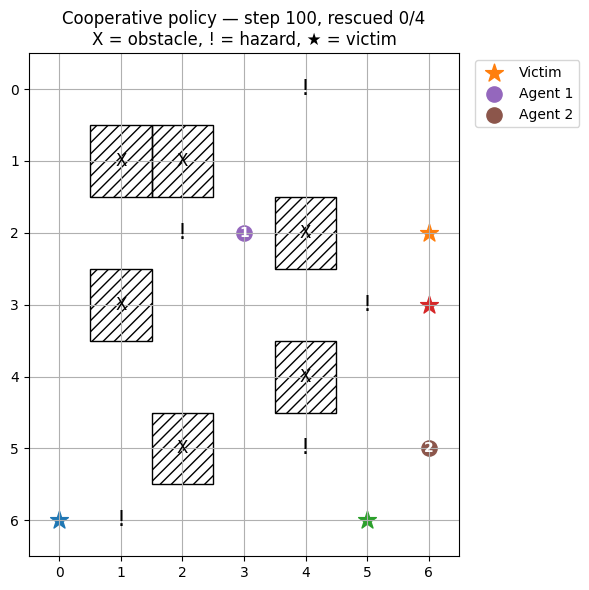

Step: 100 | Victims rescued: 0/4 | Collisions: 0 | Reward this step: -0.20


In [8]:
from IPython.display import clear_output
import time

def animate_policy(q_tables, cooperative=True, seed=777, pause=0.25):
    env = RescueEnvironment(seed=seed)
    states = env.reset()

    for step in range(env.max_steps):
        actions = []
        for i in range(N_AGENTS):
            state = env.get_shared_state(i) if cooperative else states[i]
            actions.append(int(np.argmax(q_tables[i][state])))
        next_states, rewards, done, info = env.step(actions)
        states = next_states

        clear_output(wait=True)
        draw_environment(env, f"{'Cooperative' if cooperative else 'Independent'} policy — step {step+1}, rescued {info['rescued']}/{N_VICTIMS}")
        print(f"Step: {info['steps']} | Victims rescued: {info['rescued']}/{N_VICTIMS} | Collisions: {info['collisions']} | Reward this step: {sum(rewards):.2f}")
        time.sleep(pause)
        if done:
            break

# Run this cell to see the animation. Set pause=0 for faster playback.
animate_policy(cooperative_q, cooperative=True, pause=0.2)

## 9. Inspect sample results and discuss findings

In [9]:
print("Independent learning — last 10 episodes")
display(independent_history.tail(10).round(2))

print("Cooperative learning — last 10 episodes")
display(cooperative_history.tail(10).round(2))

print("Evaluation comparison")
display(summary.round(2))

Independent learning — last 10 episodes


,episode,rescued,steps,collisions,cumulative_reward
240,241,4,12,0,37.60
241,242,4,80,0,20.75
242,243,4,8,0,36.40
243,244,4,14,0,35.20
244,245,3,100,0,8.75
245,246,4,9,1,36.70
246,247,4,10,0,34.00
247,248,4,9,0,37.20
248,249,4,10,0,34.50
249,250,4,14,0,36.70


Cooperative learning — last 10 episodes


,episode,rescued,steps,collisions,cumulative_reward
240,241,4,89,1,-10.30
241,242,4,19,0,35.20
242,243,4,63,5,15.90
243,244,2,100,0,-2.25
244,245,4,98,0,4.40
245,246,3,100,0,-3.25
246,247,4,51,0,25.05
247,248,2,100,0,-3.25
248,249,1,100,0,-15.00
249,250,4,27,0,30.60


Evaluation comparison


,Approach,Mean victims rescued,All victims rescued (%),Mean steps,Mean cumulative reward,Mean collisions
0,Independent Q-learning,2.40,30.0,73.50,-7.12,6.45
1,Cooperative Q-learning,2.08,20.0,81.75,-16.22,8.10


### Discussion / Conclusion

This experiment implements and compares independent and cooperative tabular Q-learning in a disaster-rescue grid world.

- **Independent Q-learning:** Each agent learns from its own reward signal. It is simple, but agents may not naturally coordinate and can duplicate effort or collide.
- **Cooperative Q-learning:** Agents use a shared team reward, which can encourage behavior that improves total team performance. However, a shared reward can make it harder to identify which agent's action caused a good or bad outcome.
- **Evaluation:** Compare mean victims rescued, percentage of episodes rescuing every victim, steps, cumulative reward, and collisions. Use the generated table and plots to describe which approach performed better in this run.
- **Limitations:** This small tabular setup has a simplified state representation and a small grid. It does not model communication delays, changing hazards, victim severity, or real rescue constraints. Results depend on random seeds and hyperparameters.

**Result:** A grid-based multi-agent rescue environment was created, independent and cooperative Q-learning were trained, learning curves were plotted, and both policies were evaluated using rescue success, completion time, reward, and collision metrics.

### Viva questions
1. What is multi-agent reinforcement learning (MARL)?
2. What is the difference between independent Q-learning and cooperative Q-learning?
3. Why do we use epsilon-greedy action selection?
4. What do the learning rate (α) and discount factor (γ) control?
5. Why can a shared team reward improve coordination?
6. What are the limitations of tabular Q-learning in larger environments?
7. How could the environment be improved to model real disaster response?